# Limb Sounding Observations

Limb-sounding instruments observe the atmosphere by looking sideways, toward the Earth's limb, rather than straight down at the surface. Like [GNSS Radio Occultation](CollectRO.ipynb), the observation geometry is characterized by a *tangent point*: the point along the viewing ray with minimum geodetic altitude above the WGS 84 reference ellipsoid. Unlike RO, which relies on the geometry between two independently-orbiting satellites (a receiver and a transmitter), a limb sounder's viewing ray is defined entirely by its own host spacecraft: a fixed mounting direction relative to the velocity vector, actively scanned in elevation to sweep the tangent point up and down through the atmosphere and build a vertical profile.

This TAT-C analysis function, `collect_limb_observations`, models where and when those tangent points fall as a limb-sounding spacecraft flies its orbit. As with `collect_ro_observations`, this analysis does not model atmospheric refraction and represents only a coarse geometric estimate suitable for early-stage mission analysis.

## Mathematical Basis

### Viewing Geometry

Let the satellite have position $x_{sat}$ and velocity $v_{sat}$ in a geocentric inertial frame. Define the body-fixed VNB frame (shared with the RO analysis):

$\hat{v} = \frac{v_{sat}}{||v_{sat}||}, \qquad \hat{n} = \frac{x_{sat} \times v_{sat}}{||x_{sat} \times v_{sat}||}, \qquad \hat{b} = \hat{v} \times \hat{n}$

$\hat{v}$ points along the velocity, $\hat{n}$ is normal to the orbit plane (and therefore always exactly horizontal, perpendicular to $x_{sat}$), and $\hat{b}$ completes the right-handed frame, coinciding with the zenith direction $x_{sat}/||x_{sat}||$ for a circular orbit.

The sensor's viewing direction is set by an azimuth $\psi$ (fixed, relative to velocity, measured in the local horizontal plane) and an elevation $\epsilon$ (actively scanned, the depression angle below local horizontal):

$\hat{d} = \cos\epsilon \left( \cos\psi\, \hat{v} + \sin\psi\, \hat{n} \right) - \sin\epsilon\, \hat{b}$

The tangent point is the point along the ray $x_{sat} + s\hat{d}$ with minimum WGS 84 geodetic altitude, where the ray is tangent to a surface of constant geodetic altitude. In the Earth-fixed frame, scaling the polar axis by $k = (a + h) / (b + h)$, where $a$ and $b$ are the WGS 84 equatorial and polar radii and $h$ is the target elevation, turns the surface of constant geodetic altitude $h$ into very nearly a sphere. The tangent point is then the closest approach of the scaled ray to the origin:

$s^* = -\frac{x'_{sat} \cdot \hat{d}'}{\hat{d}' \cdot \hat{d}'}, \qquad x_{tp} = x_{sat} + s^* \hat{d}$

where primes denote scaled Earth-fixed coordinates. For tangent altitudes up to about 100 km, this agrees with the exact minimum-altitude point to within a fraction of a millimeter in altitude.

### Choosing the Scan Angle

For a spherical Earth of radius $R$, the tangent point's geocentric radius depends only on the angle between $\hat{d}$ and $x_{sat}$, independent of azimuth: $r_{tp} = ||x_{sat}|| \cos\epsilon$ (for a circular orbit, where $\hat{b}$ is the local zenith). Inverting this gives the elevation angle needed to reach a target tangent point elevation $h$:

$\epsilon = \arccos\left( \frac{R + h}{||x_{sat}||} \right)$

TAT-C starts from the mean Earth radius $R_E$ and iteratively corrects $R$ by the difference between the achieved and requested geodetic altitudes until they agree to within 1 mm, usually within a few iterations. This matters for limb sounding: a single mean radius would miss the requested altitude by up to about 7 km at the equator and 14 km near the poles.

## Analysis

First, we configure the vertical scan. Four parameters set the sensor's viewing geometry:
 * `scan_azimuth` sets the sensor's fixed mounting direction (in degrees) relative to the velocity vector, measured in the local horizontal plane (0 = forward, 90 = cross-track).
 * `scan_elevations` sets the target tangent point elevations (in meters) that make up one vertical scan. Order doesn't matter here -- `scan_direction` (below) determines the sweep order -- and samples are timed across `scan_duration` as a constant angular-rate scan mirror would reach them, so unevenly-spaced elevations are not visited at evenly-spaced times.
 * `scan_duration` sets the total time to sweep through `scan_elevations`, starting at each requested scan time -- since the spacecraft keeps moving throughout the scan, this determines how much the tangent point drifts along track during a single profile.
 * `scan_direction` sets which of the two broad classes of real limb sounder scan is modeled: `UPWARD` (lowest elevation first, e.g. MLS) or `DOWNWARD` (highest first). Some instruments alternate between the two: SABER, for example, alternates upward and downward scans, which can be modeled with one call per direction. Left unset, it defaults from `scan_azimuth`: forward-looking sensors (azimuth closer to 0 deg than 180 deg) default to `UPWARD`, rearward-looking ones default to `DOWNWARD`.

These parameters approximate the geometry of [MLS](https://mls.jpl.nasa.gov/) (Microwave Limb Sounder), an instrument aboard the Aura spacecraft that views forward, along the flight direction, and scans bottom-to-top (upward) from the surface to roughly 90 km altitude in an approximately 25-second cycle (about 3,500 scans per day). Since MLS looks forward, `scan_direction` doesn't need to be set explicitly below -- it defaults to `UPWARD` automatically.

Science applications typically specify vertical levels by atmospheric pressure rather than altitude. `tatc.utils.pressure_to_altitude` converts between the two using the U.S. Standard Atmosphere (1976) model, so `scan_elevations` can be specified directly from a standard pressure grid, similar to how MLS data products are reported.

In [1]:
from datetime import datetime, timedelta, timezone
import numpy as np
from tatc.utils import pressure_to_altitude

# limb scan configuration
scan_azimuth = 0  # deg, forward (along-track) view -- defaults scan_direction to UPWARD
scan_pressures_hpa = [1000, 300, 100, 30, 10, 3, 1, 0.3, 0.1, 0.03, 0.01]
scan_elevations = [pressure_to_altitude(p * 100) for p in scan_pressures_hpa]  # m
scan_duration = timedelta(seconds=25)  # time to complete one vertical scan

# scenario configuration
start = datetime(2026, 8, 14, tzinfo=timezone.utc)
duration = timedelta(days=1)
end = start + duration
times = [start + i * scan_duration for i in range(duration // scan_duration)]
print(f"{len(times)} scans requested over {duration}")

3456 scans requested over 1 day, 0:00:00


Next, we define the spacecraft carrying the limb sounder. Aura was launched in 2004 into a sun-synchronous orbit at approximately 700 km altitude and 98.3 degree inclination as part of the A-Train constellation. The code below builds a TAT-C `Satellite` from a recent two-line element (TLE) set; note that `collect_limb_observations`, like `collect_ro_observations`, takes plain numeric arguments to describe the sensor's viewing geometry, rather than an `Instrument` schema.

In [2]:
from tatc.schemas import GeneralPerturbationsOrbit, Satellite

aura = Satellite(
    name="Aura",
    orbit=GeneralPerturbationsOrbit.from_tle(
        [
            "1 28376U 04026A   26226.59599742  .00000334  00000+0  77326-4 0  9994",
            "2 28376  98.3460 183.5488 0001688  86.3454 273.7940 14.61403667174741",
        ]
    ),
)

TAT-C simulates limb sounding observations using the `collect_limb_observations` function. For each requested start time, it samples one satellite position per `scan_elevations` entry, timed across `scan_duration` per `scan_direction` as described above, and computes that sample's tangent point.

The outputs report each vertical scan including the following fields:
 * `satellite`: the satellite name
 * `geometry`: a multipoint geometry describing the full swept tangent point track for one scan, in sweep order
 * `position`: a point geometry describing the scan interpolated at the `sample_elevation` value (defaults to the midpoint of the `scan_elevations` range, i.e., the mean of its minimum and maximum; a value outside the observed range is clamped to the nearest end of the scan)
 * `start`: time of the first valid tangent point in the scan
 * `end`: time of the last valid tangent point in the scan
 * `time`: time of the point interpolated at `sample_elevation`

In [3]:
from tatc.analysis import collect_limb_observations

limb_obs = collect_limb_observations(
    aura, times, scan_azimuth, scan_elevations, scan_duration
)
display(limb_obs)

,satellite,geometry,position,start,end,time
0,Aura,"MULTIPOINT Z ((49.60951 47.29867 110.88637), (...",POINT Z (49.559361689968455 47.30103920121651 ...,2026-08-14 00:00:00+00:00,2026-08-14 00:00:25+00:00,2026-08-14 00:00:12.318365+00:00
1,Aura,"MULTIPOINT Z ((49.04265 45.8162 110.88637), (4...",POINT Z (48.9924808394434 45.81873065456963 39...,2026-08-14 00:00:25+00:00,2026-08-14 00:00:50+00:00,2026-08-14 00:00:37.318398+00:00
2,Aura,"MULTIPOINT Z ((48.49977 44.33186 110.8855), (4...",POINT Z (48.44958568581686 44.33454456432849 3...,2026-08-14 00:00:50+00:00,2026-08-14 00:01:15+00:00,2026-08-14 00:01:02.318435+00:00
3,Aura,"MULTIPOINT Z ((47.97854 42.8458 110.88561), (4...",POINT Z (47.928330244234644 42.84863114663753 ...,2026-08-14 00:01:15+00:00,2026-08-14 00:01:40+00:00,2026-08-14 00:01:27.318474+00:00
4,Aura,"MULTIPOINT Z ((47.47687 41.35814 110.88572), (...",POINT Z (47.426643613902456 41.36111985868008 ...,2026-08-14 00:01:40+00:00,2026-08-14 00:02:05+00:00,2026-08-14 00:01:52.318515+00:00
...,...,...,...,...,...,...
3451,Aura,"MULTIPOINT Z ((-136.3017 -17.49941 110.88716),...",POINT Z (-136.35254454964755 -17.5022054747705...,2026-08-14 23:57:55+00:00,2026-08-14 23:58:20+00:00,2026-08-14 23:58:07.322794+00:00
3452,Aura,MULTIPOINT Z ((-136.64372 -16.00496 110.88708)...,POINT Z (-136.6945430763787 -16.00796584248263...,2026-08-14 23:58:20+00:00,2026-08-14 23:58:45+00:00,2026-08-14 23:58:32.322769+00:00
3453,Aura,"MULTIPOINT Z ((-136.98227 -14.50979 110.887), ...",POINT Z (-137.03308227285584 -14.5129914835925...,2026-08-14 23:58:45+00:00,2026-08-14 23:59:10+00:00,2026-08-14 23:58:57.322743+00:00
3454,Aura,"MULTIPOINT Z ((-137.31775 -13.0139 110.88691),...",POINT Z (-137.36855145260222 -13.0172953175825...,2026-08-14 23:59:10+00:00,2026-08-14 23:59:35+00:00,2026-08-14 23:59:22.322715+00:00


The limb observations can be better visualized by combining with the satellite's orbit track.

In [4]:
from tatc.analysis import collect_orbit_track

orbit_track = collect_orbit_track(aura, times)

The resulting plot shows the Aura orbit track together with each vertical scan's `position`: its tangent point interpolated at `sample_elevation` (here, the default midpoint of the `scan_elevations` range).

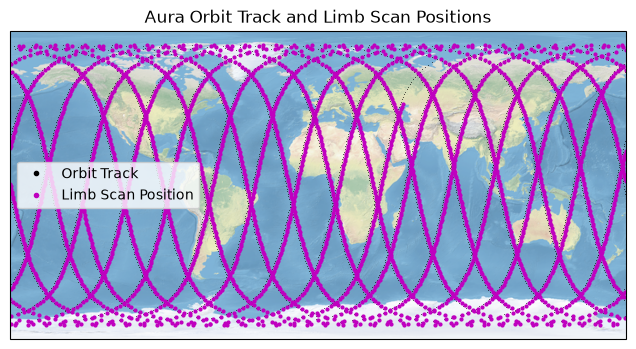

In [5]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import cartopy.crs as ccrs

fig, ax = plt.subplots(figsize=(10, 4), subplot_kw={"projection": ccrs.PlateCarree()})
orbit_track.plot(
    ax=ax, marker=".", color="k", markersize=1, lw=0, transform=ccrs.PlateCarree()
)
ax.scatter(
    [p.x for p in limb_obs.position],
    [p.y for p in limb_obs.position],
    color="m",
    s=4,
    transform=ccrs.PlateCarree(),
)
ax.stock_img()
ax.set_global()
ax.legend(
    handles=[
        Line2D([0], [0], marker=".", color="k", lw=0, label="Orbit Track"),
        Line2D([0], [0], marker=".", color="m", lw=0, label="Limb Scan Position"),
    ]
)
ax.set_title("Aura Orbit Track and Limb Scan Positions")
plt.show()

Each row's `geometry` traces a single vertical scan. Plotting one scan's tangent point elevation against its sample index shows the vertical profile through the atmosphere that a limb sounder builds as it sweeps `scan_elevations`.

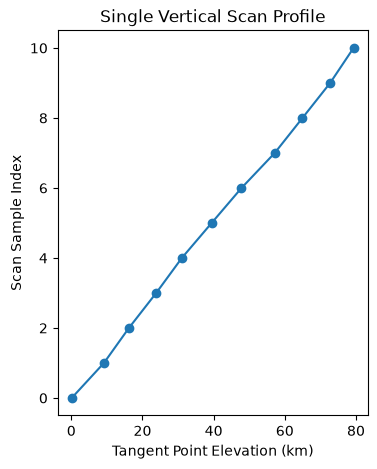

In [6]:
fig, ax = plt.subplots(figsize=(4, 5))

sample_scan = limb_obs.iloc[len(limb_obs) // 2].geometry
heights_km = [p.z / 1e3 for p in sample_scan.geoms]

ax.plot(heights_km, range(len(heights_km)), marker="o")
ax.set_xlabel("Tangent Point Elevation (km)")
ax.set_ylabel("Scan Sample Index")
ax.set_title("Single Vertical Scan Profile")
plt.show()

An animation can show the dynamic collection of vertical scan positions aggregated to individual (hourly) frames. The animation is an animated WebP image embedded in the notebook, which plays in a loop.

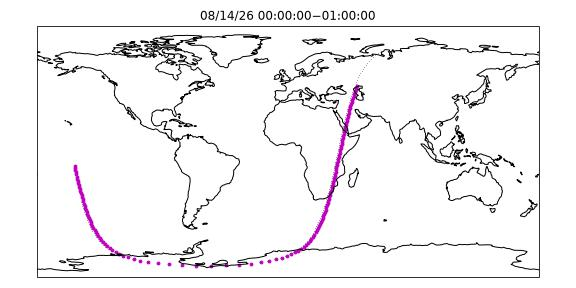

In [7]:
import base64
from io import BytesIO

from IPython.display import display
from PIL import Image

fig, ax = plt.subplots(
    figsize=(8, 4), dpi=72, subplot_kw={"projection": ccrs.PlateCarree()}
)

frame_duration = timedelta(hours=1)
num_frames = int(duration / frame_duration)


def animate(frame):
    ax.clear()
    time = times[0] + frame * frame_duration
    orbit_track.loc[
        (orbit_track.time >= time) & (orbit_track.time < time + frame_duration)
    ].plot(
        ax=ax, marker=".", color="k", markersize=1, lw=0, transform=ccrs.PlateCarree()
    )
    frame_obs = limb_obs.loc[
        (limb_obs.start >= time) & (limb_obs.start < time + frame_duration)
    ]
    if not frame_obs.empty:
        ax.scatter(
            [p.x for p in frame_obs.position],
            [p.y for p in frame_obs.position],
            color="m",
            s=8,
            transform=ccrs.PlateCarree(),
        )
    ax.set_global()
    ax.coastlines()
    ax.set_aspect("equal")
    ax.set_title(
        time.strftime("%x %X") + "$-$" + (time + frame_duration).strftime("%X")
    )
    fig.tight_layout()


def render_frame(frame):
    """The figure of a frame, as an image."""
    animate(frame)
    fig.canvas.draw()
    return Image.fromarray(np.asarray(fig.canvas.buffer_rgba())).convert("RGB")


def encode(image, **kwargs):
    """An image file, encoded as base64 text to embed in the notebook."""
    buffer = BytesIO()
    image.save(buffer, **kwargs)
    return base64.b64encode(buffer.getvalue()).decode()


frames = [render_frame(frame) for frame in range(num_frames)]
plt.close(fig)
webp = encode(
    frames[0],
    format="WEBP",
    save_all=True,
    append_images=frames[1:],
    duration=200,
    loop=0,
    quality=75,
    method=6,  # the slowest and smallest encoding
)
# An animated image in HTML, with the first frame as a still image for viewers without HTML.
display(
    {
        "text/html": f'<img src="data:image/webp;base64,{webp}" alt="Animation of the limb scan positions collected in each hour">',
        "image/jpeg": encode(frames[0], format="JPEG", quality=75, optimize=True),
    },
    raw=True,
)